In [3]:
import numpy as np
import matplotlib.pyplot as plt

In [4]:
x_data = np.array([0, 200, 400, 800, 1200, 1600])
y_data = np.array([0, 0.09, 0.18, 0.40, 0.53, 0.55])

In [5]:
not_zero = x_data > 0
individual_slopes = y_data[not_zero] / x_data[not_zero]
slope = np.median(individual_slopes)

In [6]:
def getConcentration(absorbance):
    return absorbance / slope

In [7]:
fitted_y = slope * x_data
deviations = np.abs(y_data - fitted_y)
is_outlier = deviations >= 0.04

In [8]:
unknown_absorbance = 0.49
unknown_concentration = getConcentration(unknown_absorbance)

In [9]:
x_fit = np.linspace(0, 1800, 100)
y_fit = slope * x_fit

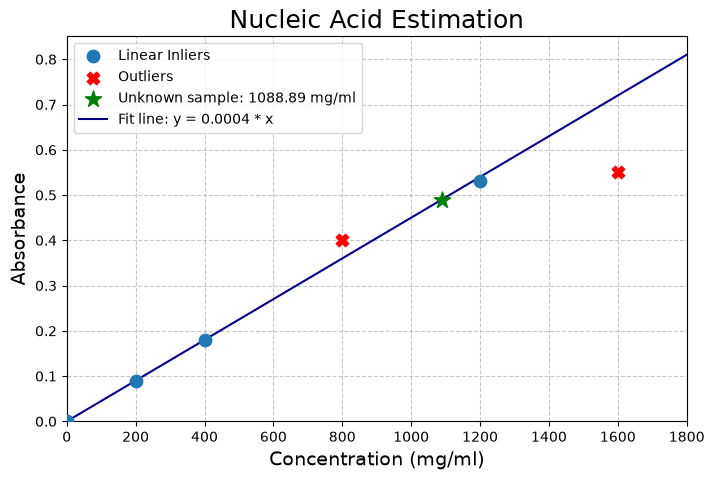

In [10]:
plt.figure(figsize=(8, 5))
plt.scatter(x_data[~is_outlier], y_data[~is_outlier], label='Linear Inliers', zorder=5, s=80)
plt.scatter(x_data[is_outlier], y_data[is_outlier], label='Outliers', color='red', marker='X', s=80, zorder=5)
plt.scatter(unknown_concentration, unknown_absorbance, marker='*', s=150, label=f'Unknown sample: {unknown_concentration:.2f} mg/ml', color='green', zorder=5)
plt.plot(x_fit, y_fit, '-', label=f'Fit line: y = {slope:.4f} * x', color='darkblue')
plt.xlabel('Concentration (mg/ml)', size=14)
plt.ylabel('Absorbance', size=14)
plt.title('Nucleic Acid Estimation', size=18)
plt.xlim(left=0, right=1800)
plt.ylim(bottom=0)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()